# DỰ ĐOÁN ĐỘ TRỄ MẠNG (RTT - Round Trip Time)

## 1. Giới thiệu bài toán
Mục tiêu của bài toán là dự đoán độ trễ trung bình khi gửi và nhận gói tin tới máy chủ đích (`rtt_avg_ms`) dựa trên các đặc trưng về mạng (Network features) và thời gian (Time features).

## 2. Định nghĩa Input (X) và Output (Y)

### 🔹 INPUT (X) - Các đặc trưng đầu vào:
| Feature | Ý nghĩa |
| :--- | :--- |
| `gateway_rtt_avg_ms` | Độ trễ trung bình tới Gateway |

### 🔸 OUTPUT (Y) - Biến mục tiêu:
| Feature | Ý nghĩa |
| :--- | :--- |
| `rtt_avg_ms` | Độ trễ trung bình khi gửi và nhận gói tin tới máy chủ đích (đơn vị milliseconds - ms) |

In [ ]:
# Cell 1: Tải dữ liệu từ Google Drive và Đọc dữ liệu (Chỉ lấy 1 feature Input)

import os
import pandas as pd

# 1. Cài đặt thư viện gdown nếu chưa có (dành cho Colab/Jupyter)
try:
    import gdown
except ImportError:
    !pip install gdown -q
    import gdown

# 2. Tải file từ Google Drive (ID trích xuất từ link của bạn)
file_id = '1RgrGtIgDJQiuYjxZ3WSxESXdaZztoj9T'
download_path = 'dataset.csv' # Đổi đuôi thành .xlsx nếu file của bạn là Excel

if not os.path.exists(download_path):
    print("Đang tải dữ liệu từ Google Drive...")
    gdown.download(id=file_id, output=download_path, quiet=False)
    print("Tải thành công!")
else:
    print("File đã tồn tại, bỏ qua bước tải.")

# 3. Đọc dữ liệu
try:
    # Nếu file tải về là Excel, hãy đổi thành pd.read_excel(download_path)
    df = pd.read_csv(download_path)
    print(f"\nKích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột.")

    # Hiển thị 5 dòng đầu tiên
    display(df.head())

    # 4. KHAI BÁO BIẾN (CHỈ LẤY 1 CỘT INPUT)
    X_feature = ['gateway_rtt_avg_ms'] # Chỉ lấy duy nhất cột này làm Input
    target_y = 'rtt_avg_ms'            # Cột Output

    print("\n--- Kiểm tra sự tồn tại của các cột ---")
    required_cols = X_feature + [target_y]
    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        print(f"⚠️ Cảnh báo: Các cột sau không tìm thấy trong file: {missing_cols}")
    else:
        print(f"✅ Đã tìm thấy cột Input: {X_feature}")
        print(f"✅ Đã tìm thấy cột Output: {target_y}")

        # Trích xuất ra X và y (Tùy chọn, dùng cho các bước sau)
        # X = df[X_feature]
        # y = df[target_y]

except Exception as e:
    print(f"Có lỗi khi đọc file: {e}")
    print("Vui lòng kiểm tra lại định dạng file (CSV, Excel, ZIP...) để dùng hàm đọc phù hợp.")

File đã tồn tại, bỏ qua bước tải.


In [ ]:
from sklearn.model_selection import train_test_split
X, y = df[X_feature], df[target_y]
# Làm sạch dữ liệu null trực tiếp trên X và y bằng Pandas
clean_data = pd.concat([X, y], axis=1).dropna()
X, y = clean_data[X_feature], clean_data[target_y]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#2. Khám phá và trực quan hóa tập dữ liệu:


In [ ]:
#Cell 2
!pip install datasets


--- PHẦN 2: EDA VÀ TRỰC QUAN HÓA (XỬ LÝ OUTLIERS) ---
Kích thước dữ liệu sạch sau khi loại bỏ null cho EDA: (54589, 5)


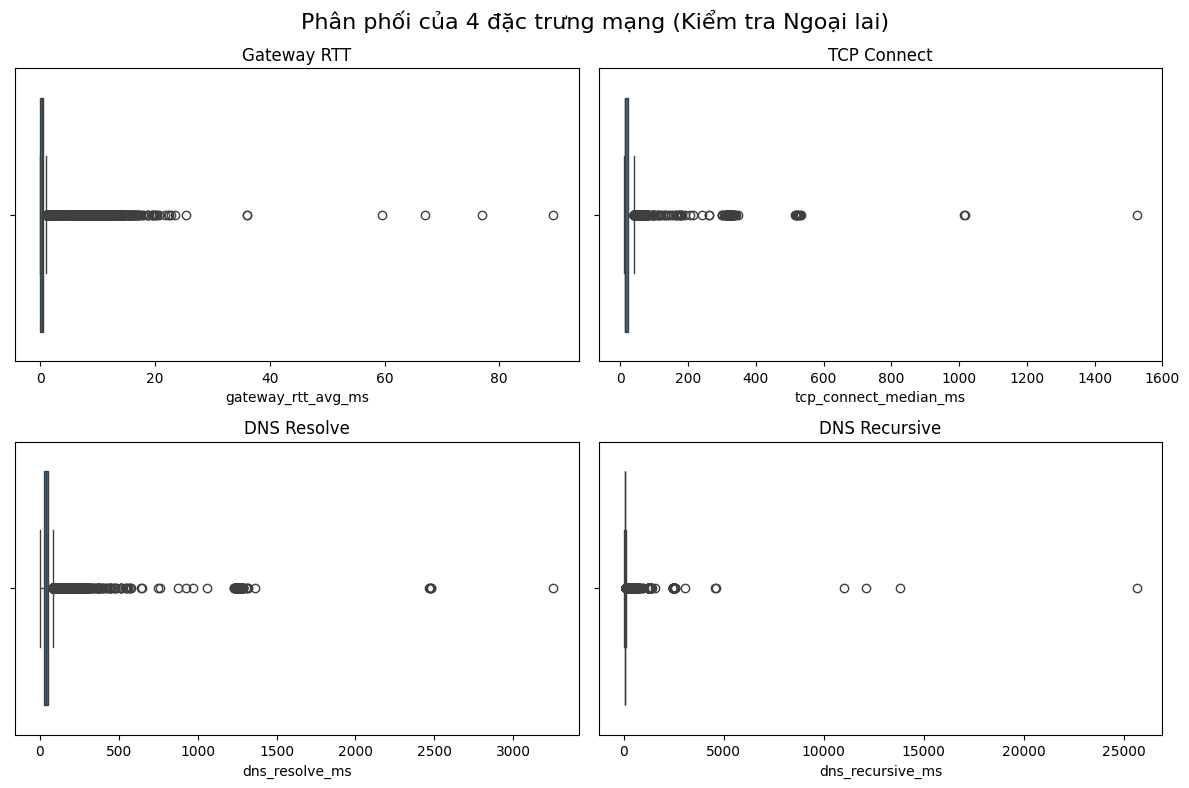

=> ĐÃ LƯU SƠ ĐỒ PHÂN PHỐI: eda_distributions.png

--- HỆ SỐ TƯƠNG QUAN PEARSON ---
rtt_avg_ms               1.000000
tcp_connect_median_ms    0.252810
gateway_rtt_avg_ms       0.197710
dns_recursive_ms         0.040121
dns_resolve_ms           0.029868
Name: rtt_avg_ms, dtype: float64


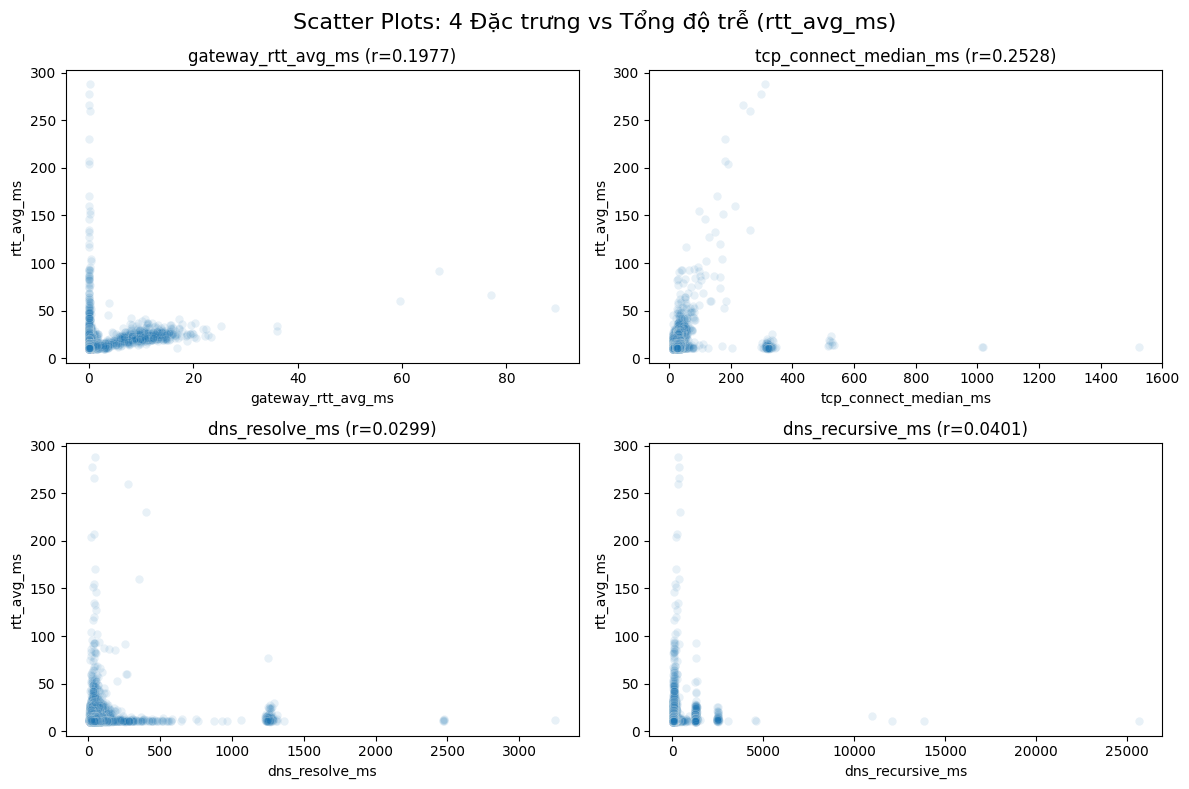

=> ĐÃ LƯU SƠ ĐỒ SCATTER: Task2_Compare_4_Features_ScatterPlots.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- PHẦN 2: EDA VÀ TRỰC QUAN HÓA (XỬ LÝ OUTLIERS) ---")

# Khắc phục lỗi: Tạo biến df_clean bằng cách lấy 4 đặc trưng mạng + cột target từ df gốc và loại bỏ null
features_for_eda = ['gateway_rtt_avg_ms', 'tcp_connect_median_ms', 'dns_resolve_ms', 'dns_recursive_ms', 'rtt_avg_ms']
try:
    df_clean = df[features_for_eda].dropna().copy()
    print(f"Kích thước dữ liệu sạch sau khi loại bỏ null cho EDA: {df_clean.shape}")
except NameError:
    print(" LỖI CRITICAL: Không tìm thấy biến 'df' gốc!")
    print(" Cách sửa: Anh phải cuộn lên CÁC CELL ĐẦU TIÊN (Phần 1. Đọc dữ liệu) và CHẠY LẠI CHÚNG để nạp data vào bộ nhớ trước khi chạy Cell này!")
    raise
except KeyError as e:
    print(f"\n LỖI: Thiếu cột {e} trong dữ liệu gốc!")
    print(" Cách sửa: Ở Cell 1, anh đang lỡ dùng code xóa mất các cột này rồi. Hãy sửa Cell 1 để nạp TOÀN BỘ các cột nhé!")
    raise

# 1. Vẽ sơ đồ phân phối (Boxplots) để phân tích Outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Phân phối của 4 đặc trưng mạng (Kiểm tra Ngoại lai)', fontsize=16)

sns.boxplot(ax=axes[0, 0], x=df_clean['gateway_rtt_avg_ms']).set_title('Gateway RTT')
sns.boxplot(ax=axes[0, 1], x=df_clean['tcp_connect_median_ms']).set_title('TCP Connect')
sns.boxplot(ax=axes[1, 0], x=df_clean['dns_resolve_ms']).set_title('DNS Resolve')
sns.boxplot(ax=axes[1, 1], x=df_clean['dns_recursive_ms']).set_title('DNS Recursive')

plt.tight_layout()
plt.savefig('eda_distributions.png', dpi=300)
plt.show()
print("=> ĐÃ LƯU SƠ ĐỒ PHÂN PHỐI: eda_distributions.png")

# 2. In hệ số tương quan Pearson
print("\n--- HỆ SỐ TƯƠNG QUAN PEARSON ---")
correlations = df_clean.corr()['rtt_avg_ms'].sort_values(ascending=False)
print(correlations)

# 3. Vẽ sơ đồ Scatter Plots hình chữ L
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Scatter Plots: 4 Đặc trưng vs Tổng độ trễ (rtt_avg_ms)', fontsize=16)

sns.scatterplot(ax=axes[0, 0], x=df_clean['gateway_rtt_avg_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[0, 0].set_title(f"gateway_rtt_avg_ms (r={correlations['gateway_rtt_avg_ms']:.4f})")

sns.scatterplot(ax=axes[0, 1], x=df_clean['tcp_connect_median_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[0, 1].set_title(f"tcp_connect_median_ms (r={correlations['tcp_connect_median_ms']:.4f})")

sns.scatterplot(ax=axes[1, 0], x=df_clean['dns_resolve_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[1, 0].set_title(f"dns_resolve_ms (r={correlations['dns_resolve_ms']:.4f})")

sns.scatterplot(ax=axes[1, 1], x=df_clean['dns_recursive_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[1, 1].set_title(f"dns_recursive_ms (r={correlations['dns_recursive_ms']:.4f})")

plt.tight_layout()
plt.savefig('Task2_Compare_4_Features_ScatterPlots.png', dpi=300)
plt.show()
print("=> ĐÃ LƯU SƠ ĐỒ SCATTER: Task2_Compare_4_Features_ScatterPlots.png")

In [ ]:
print("\n--- CÁC TỨ PHÂN VỊ (Q1, Q2, Q3) CỦA 4 ĐẶC TRƯNG ---")
features = ['gateway_rtt_avg_ms', 'tcp_connect_median_ms', 'dns_resolve_ms', 'dns_recursive_ms']

for col in features:
    q1 = df_clean[col].quantile(0.25)
    q2 = df_clean[col].quantile(0.50)
    q3 = df_clean[col].quantile(0.75)
    print(f"[{col}]")
    print(f"  Q1 (25%): {q1:.2f} ms")
    print(f"  Q2 (50% - Median): {q2:.2f} ms")
    print(f"  Q3 (75%): {q3:.2f} ms")
    print("-" * 30)


--- CÁC TỨ PHÂN VỊ (Q1, Q2, Q3) CỦA 4 ĐẶC TRƯNG ---
[gateway_rtt_avg_ms]
  Q1 (25%): 0.00 ms
  Q2 (50% - Median): 0.20 ms
  Q3 (75%): 0.40 ms
------------------------------
[tcp_connect_median_ms]
  Q1 (25%): 12.97 ms
  Q2 (50% - Median): 14.48 ms
  Q3 (75%): 23.94 ms
------------------------------
[dns_resolve_ms]
  Q1 (25%): 27.03 ms
  Q2 (50% - Median): 36.02 ms
  Q3 (75%): 48.19 ms
------------------------------
[dns_recursive_ms]
  Q1 (25%): 47.21 ms
  Q2 (50% - Median): 59.24 ms
  Q3 (75%): 72.50 ms
------------------------------


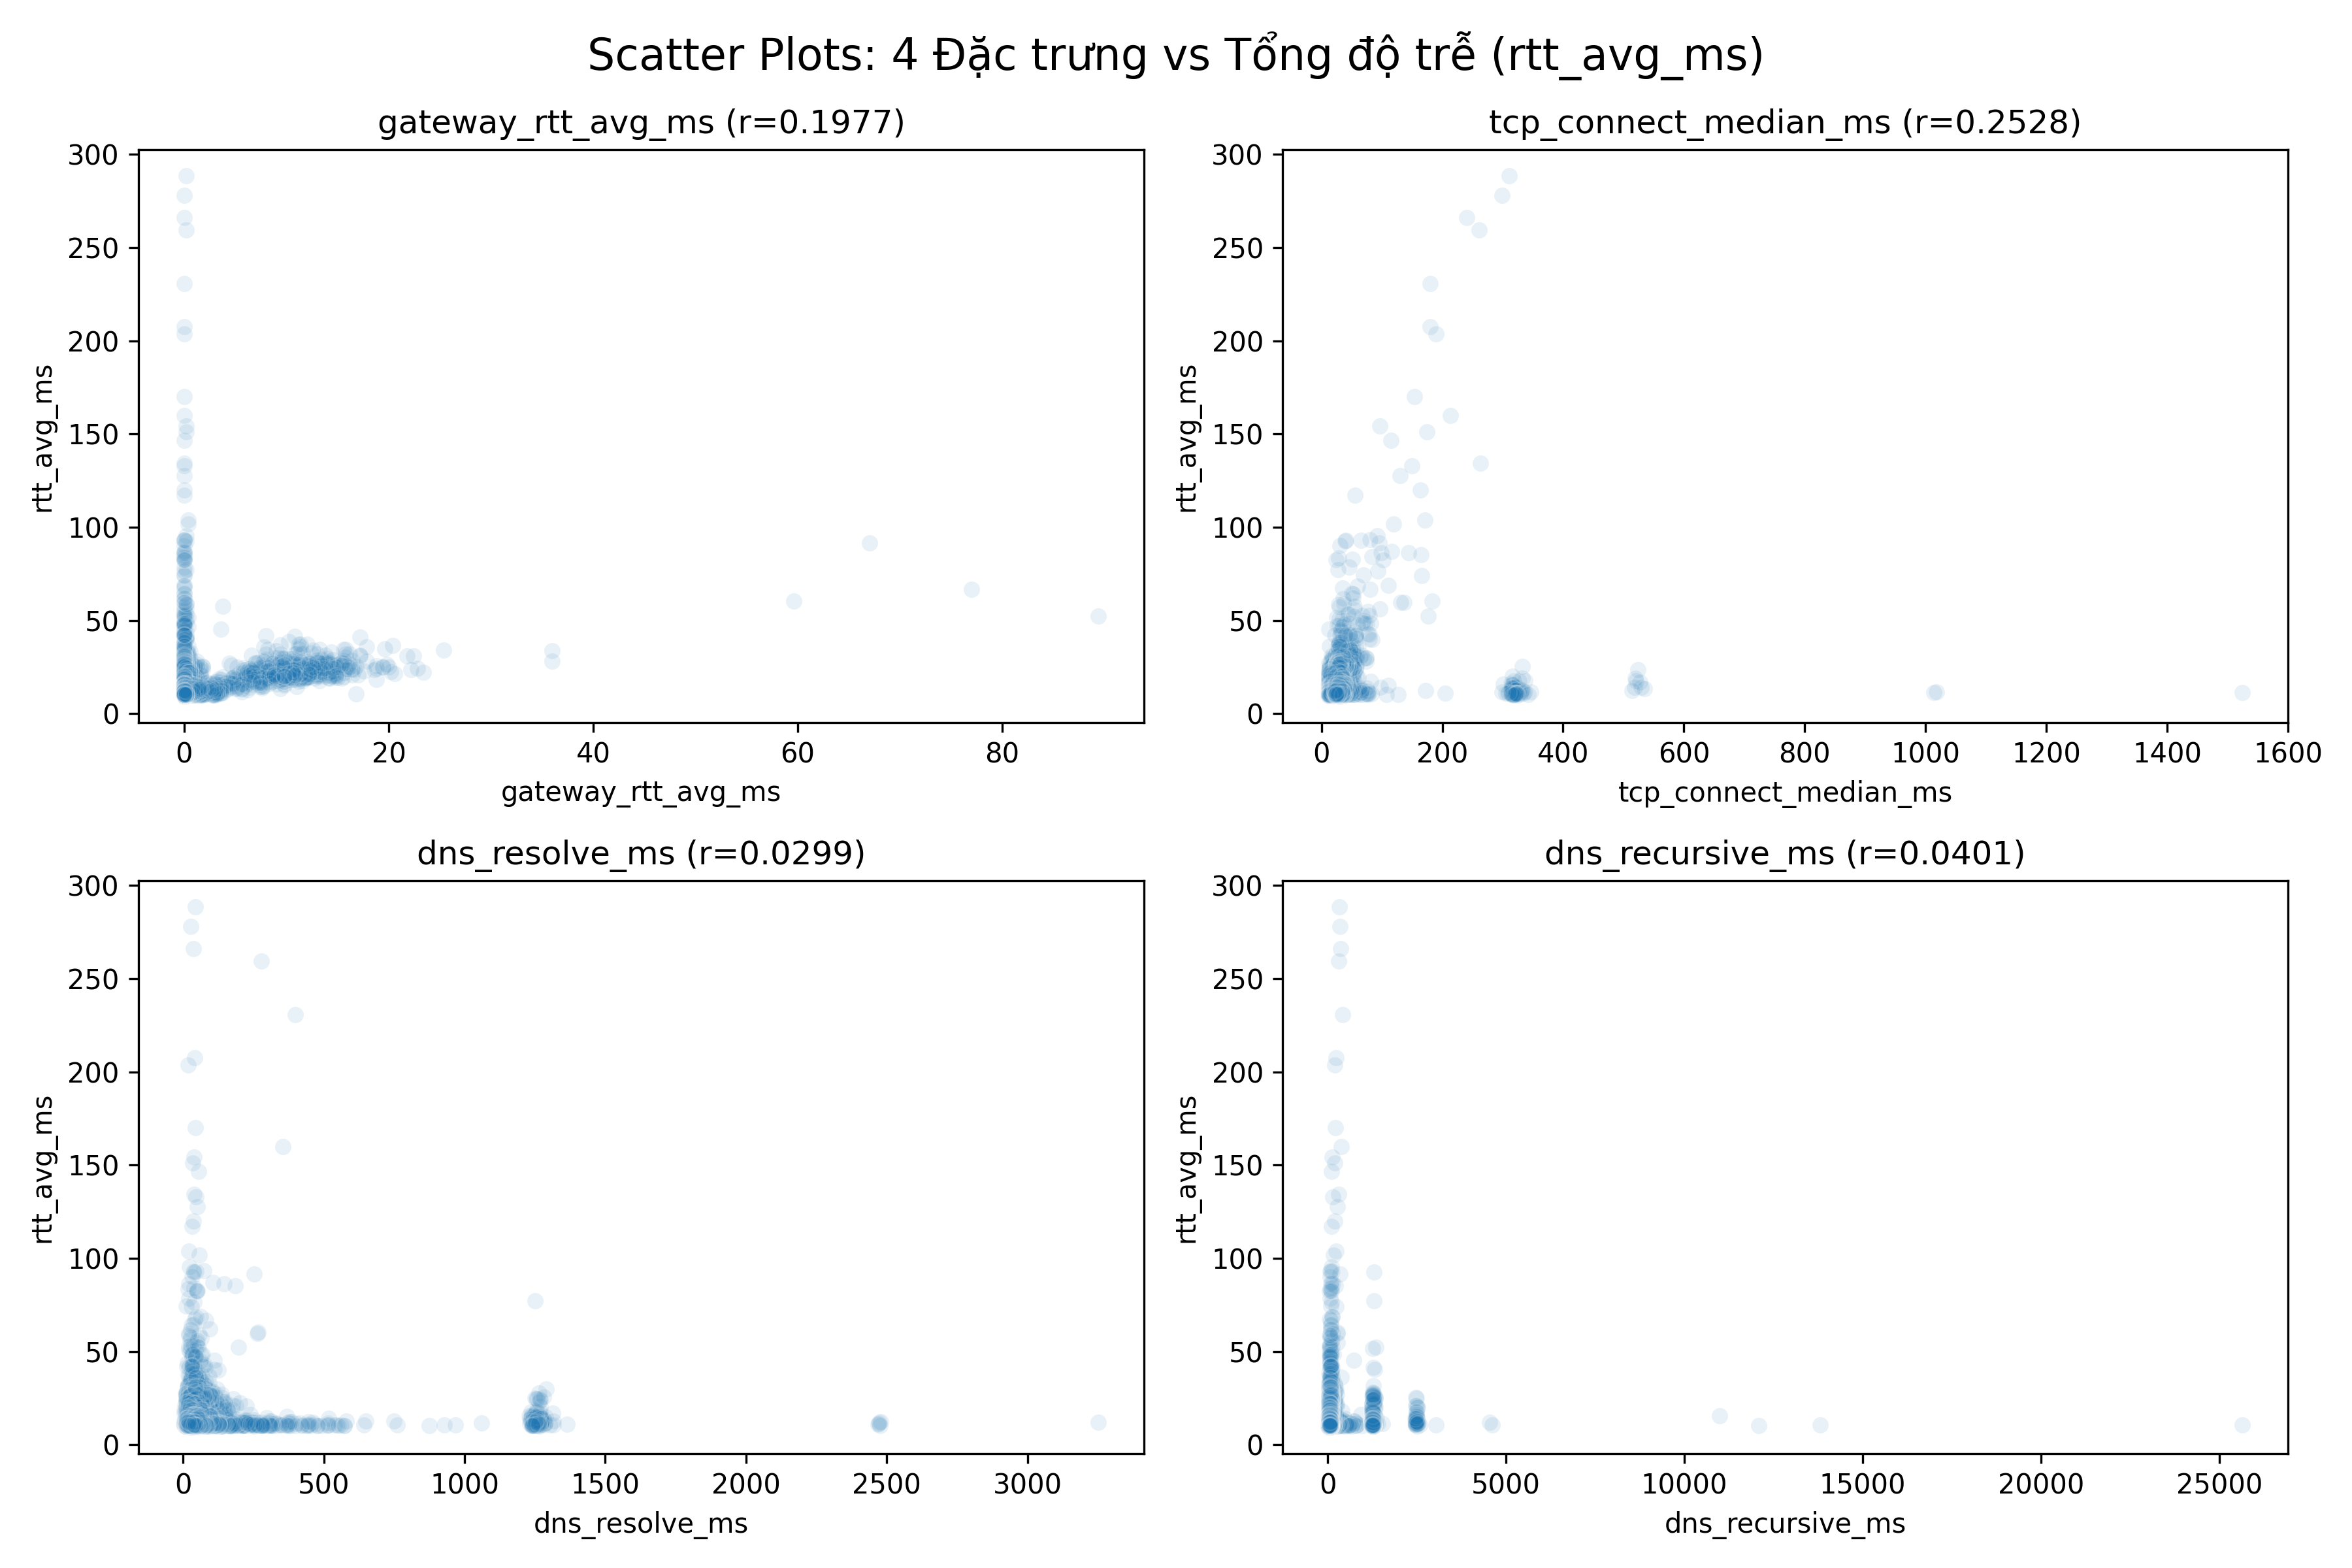

In [ ]:
import os
from IPython.display import Image, display

image_path = 'Task2_Compare_4_Features_ScatterPlots.png'
if os.path.exists(image_path):
    display(Image(image_path))
else:
    print(f"⚠️ Cảnh báo: File ảnh '{image_path}' chưa được tạo.")
    print("Lý do: Cell EDA phía trên (ID: 522fuUCAsuXN) bị lỗi do biến 'df_clean' chưa được định nghĩa.")

### 3. Tính hàm mất mát bình phương trung bình (MSE Cost Function $J(\theta)$)

Mô hình hồi quy tuyến tính đơn biến có dạng:
$$f_{\theta}(x) = \theta_0 + \theta_1 x_1 = X\theta$$

Hàm mất mát đo lường sai số giữa giá trị dự đoán $f_{\theta}(x^{(i)})$ và giá trị thực tế $y^{(i)}$ trên tập dữ liệu gồm $n$ quan sát:
$$J(\theta) = \frac{1}{2n}\sum_{i=1}^{n}\left(f_{\theta}(x^{(i)}) - y^{(i)}\right)^2 = \frac{1}{2n}\|X\theta - y\|_2^2$$

In [ ]:
# Cell 3: Tính hàm mất mát MSE J(theta) dựa trên tập Train
import numpy as np

# 1. TẠO MA TRẬN THIẾT KẾ VÀ DỌN DẸP DỮ LIỆU RỖNG
# TRỌNG TÂM FIX LỖI TRÀN RAM: Ép cả x và y về mảng 1 chiều (flatten) TRƯỚC khi so sánh
# để tránh lỗi NumPy tự động tạo ma trận khổng lồ (Broadcasting) n x n.
x_flat = np.array(X_train).astype(float).flatten()
y_flat = np.array(y_train).astype(float).flatten()

# Tìm và loại bỏ các hàng bị thiếu dữ liệu (NaN) trên 2 mảng 1 chiều (kích thước 1-1)
# valid_mask = ~np.isnan(x_flat) & ~np.isnan(y_flat)

# Lọc lấy các giá trị sạch
x_clean = x_flat[:]
y_clean = y_flat[:]
n_train_samples = len(y_clean)

# Đưa y_clean trở lại dạng vector cột (n, 1) để nhân ma trận
y_train_vec = y_clean.reshape(-1, 1)

# Thêm cột số 1 vào đằng trước x_clean để khớp với hệ số chặn theta_0
X_train_design = np.column_stack((np.ones(n_train_samples), x_clean))

print(f"Số lượng mẫu Train (đã dọn sạch lỗi rỗng): {n_train_samples}")
print(f"Kích thước X_train_design: {X_train_design.shape}")
print(f"Kích thước y_train_vec: {y_train_vec.shape}")

# 2. HÀM TÍNH COST
def compute_cost(feat_matrix, target_vector, theta_params):
    num_samples = len(target_vector)
    predictions = feat_matrix @ theta_params
    errors = predictions - target_vector
    cost = (1 / (2 * num_samples)) * np.sum(errors ** 2)
    return float(cost)

# Khởi tạo theta ban đầu và tính thử cost trên tập Train
theta_start = np.zeros((2, 1))
initial_cost = compute_cost(X_train_design, y_train_vec, theta_start)
print(f"Giá trị Cost ban đầu J(theta) trên tập Train: {initial_cost:.6f}")

Số lượng mẫu Train (đã dọn sạch lỗi rỗng): 43679
Kích thước X_train_design: (43679, 2)
Kích thước y_train_vec: (43679, 1)
Giá trị Cost ban đầu J(theta) trên tập Train: 92.167763


### 4. Cài đặt thuật toán Gradient Descent

Quy tắc cập nhật tham số ngược hướng đạo hàm với tốc độ học (learning rate) $\gamma > 0$:
$$\theta := \theta - \gamma \nabla_{\theta}J(\theta)^\top$$

Trong đó vector đạo hàm riêng được biểu diễn dưới dạng ma trận:
$$\nabla_{\theta}J(\theta)^\top = \frac{1}{n}X^\top(X\theta - y)$$

In [ ]:
# Cell 4: Thực thi Gradient Descent trên tập Train
def gradient_descent(feat_matrix, target_vector, theta_init, learning_rate=0.0001, num_iterations=1000):
    num_samples = len(target_vector)
    theta_current = theta_init.copy().astype(float)
    cost_history = []
    theta_history = [theta_current.copy()]

    for i in range(1, num_iterations + 1):
        # Tính sai số: h(x) - y
        errors = (feat_matrix @ theta_current) - target_vector

        # Đạo hàm Gradient
        grad = (1 / num_samples) * (feat_matrix.T @ errors)

        # Cập nhật theta
        theta_current = theta_current - learning_rate * grad

        # Lưu lịch sử
        current_cost = compute_cost(feat_matrix, target_vector, theta_current)
        cost_history.append(current_cost)
        theta_history.append(theta_current.copy())

        if i in [1, 2, 3, 100, 500, num_iterations]:
            print(f"Vòng {i:4d} | theta_0 = {theta_current[0,0]:.6f}, theta_1 = {theta_current[1,0]:.6f} | J = {current_cost:.6f}")

    return theta_current, np.array(cost_history), np.array(theta_history)

# TRỌNG TÂM SỬA LỖI NaN: Hạ learning_rate xuống cực nhỏ (0.0001) và tăng vòng lặp lên 1000
theta_gd, cost_hist_gd, theta_hist_gd = gradient_descent(
    X_train_design, y_train_vec, theta_start, learning_rate=0.01, num_iterations=1000
)

print("\n=== KẾT QUẢ GRADIENT DESCENT (TRAIN SET) ===")
print(f"Theta tối ưu: {theta_gd.flatten()}")

Vòng    1 | theta_0 = 0.125830, theta_1 = 0.054541 | J = 90.299749
Vòng    2 | theta_0 = 0.250225, theta_1 = 0.107706 | J = 88.482058
Vòng    3 | theta_0 = 0.373205, theta_1 = 0.159524 | J = 86.713149
Vòng  100 | theta_0 = 7.689165, theta_1 = 1.721454 | J = 22.496615
Vòng  500 | theta_0 = 12.188765, theta_1 = 0.875988 | J = 12.431996
Vòng 1000 | theta_0 = 12.313184, theta_1 = 0.831447 | J = 12.424097

=== KẾT QUẢ GRADIENT DESCENT (TRAIN SET) ===
Theta tối ưu: [12.31318397  0.83144724]


### 5. Nghiệm giải tích bình phương tối thiểu (Analytical Least-Squares Solution)

Cho đạo hàm bằng $0$ ($\nabla_{\theta}J(\theta) = 0$), ta thu được hệ Phương trình chuẩn (Normal Equations):
$$(X^\top X)\theta = X^\top y \implies \theta^* = (X^\top X)^{-1} X^\top y$$

In [ ]:
# Cell 5: Nghiệm giải tích Normal Equation trên tập Train
def compute_analytical_solution(feat_matrix, target_vector):
    mat_T_mat = feat_matrix.T @ feat_matrix
    mat_T_vec = feat_matrix.T @ target_vector
    theta_exact = np.linalg.inv(mat_T_mat) @ mat_T_vec
    return theta_exact, mat_T_mat, mat_T_vec

theta_analytical, mat_T_mat, mat_T_vec = compute_analytical_solution(X_train_design, y_train_vec)
cost_analytical = compute_cost(X_train_design, y_train_vec, theta_analytical)

print("=== SO SÁNH HAI PHƯƠNG PHÁP TRÊN TẬP TRAIN ===")
print(f"Theta Gradient Descent : {theta_gd.flatten()}")
print(f"Theta Normal Equation  : {theta_analytical.flatten()}")
print(f"Sai lệch hàm Cost      : {abs(cost_hist_gd[-1] - cost_analytical):.2e}")

=== SO SÁNH HAI PHƯƠNG PHÁP TRÊN TẬP TRAIN ===
Theta Gradient Descent : [12.31318397  0.83144724]
Theta Normal Equation  : [12.31467254  0.83090994]
Sai lệch hàm Cost      : 1.11e-06


## 6. Cost function landscape and optimization trajectory

CHI TIẾT QUÁ TRÌNH TỐI ƯU HÓA 
--- ĐIỂM BẮT ĐẦU (Vòng 0) ---
  Theta_0 : 0.000000
  Theta_1 : 0.000000
  Cost J  : 92.167763

--- ĐIỂM KẾT THÚC (Vòng 1000) ---
  Theta_0 : 12.313184
  Theta_1 : 0.831447
  Cost J  : 12.424097

--- NGHIỆM CHÍNH XÁC (Analytical) ---
  Theta_0 : 12.314673
  Theta_1 : 0.830910
  Cost J  : 12.424096

--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---
  Delta Theta_0 : 0.001489
  Delta Theta_1 : 0.000537
  Delta Cost    : 0.000001



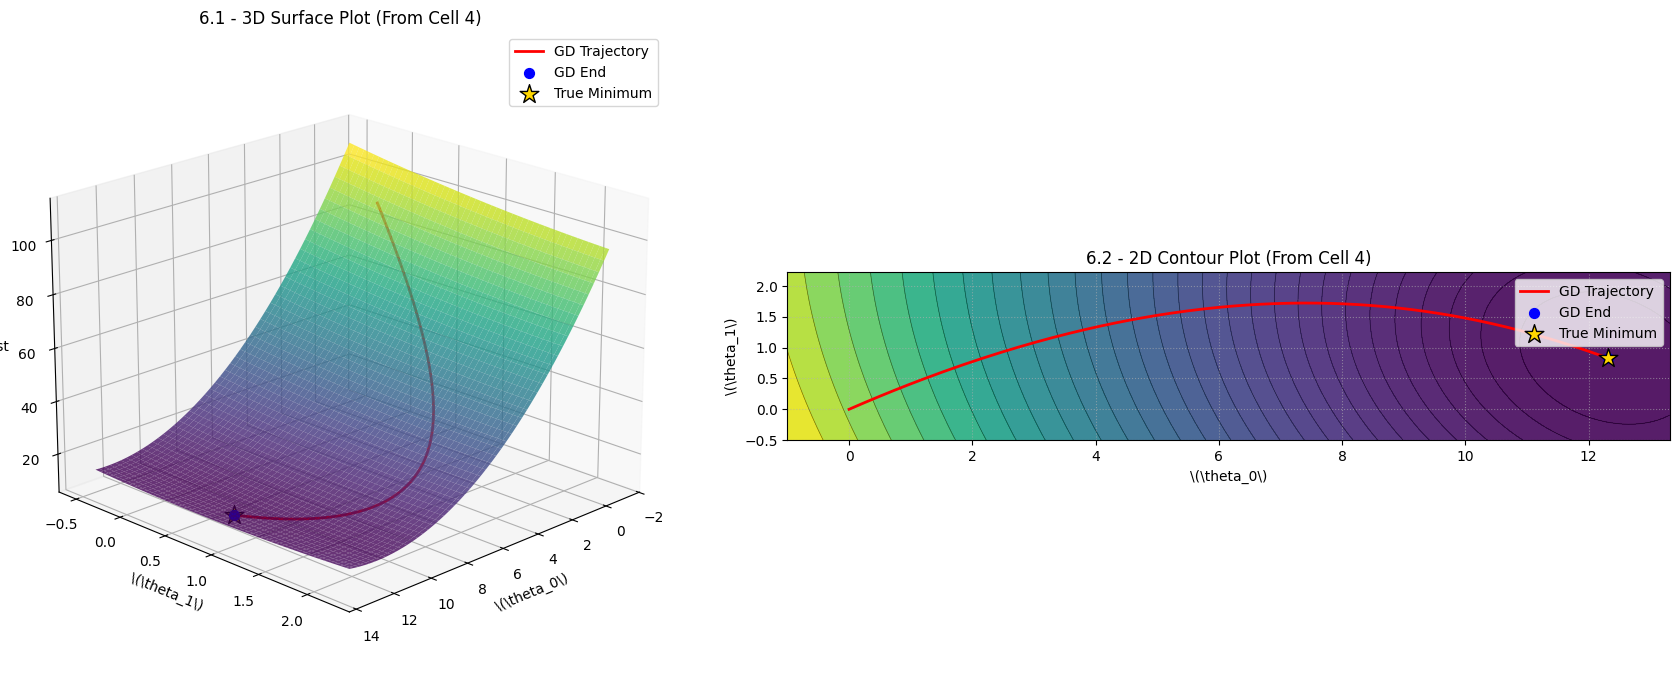

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# PHẦN 1: LẤY DỮ LIỆU TỪ CELL 4 & NGHIỆM CHÍNH XÁC
# ==========================================
# Lấy quỹ đạo theta từ Cell 4
t0_hist = theta_hist_gd[:, 0, 0]
t1_hist = theta_hist_gd[:, 1, 0]

# Lấy lịch sử cost từ Cell 4 và thêm điểm bắt đầu (vòng 0)
cost_init = compute_cost(X_train_design, y_train_vec, theta_start)
cost_hist_full = np.insert(cost_hist_gd, 0, cost_init)

# Tính nghiệm chính xác (Analytical) để làm tâm đồ thị
theta_analytical = np.linalg.inv(X_train_design.T @ X_train_design) @ (X_train_design.T @ y_train_vec)
cost_analytical = compute_cost(X_train_design, y_train_vec, theta_analytical)

center_t0 = theta_analytical[0, 0]
center_t1 = theta_analytical[1, 0]


# ==========================================
# [MỚI] PHẦN LOG CHI TIẾT ĐẦU VÀ CUỐI
# ==========================================
print("="*55)
print("CHI TIẾT QUÁ TRÌNH TỐI ƯU HÓA ")
print("="*55)
print("--- ĐIỂM BẮT ĐẦU (Vòng 0) ---")
print(f"  Theta_0 : {t0_hist[0]:.6f}")
print(f"  Theta_1 : {t1_hist[0]:.6f}")
print(f"  Cost J  : {cost_init:.6f}")

print(f"\n--- ĐIỂM KẾT THÚC (Vòng {len(t0_hist)-1}) ---")
print(f"  Theta_0 : {t0_hist[-1]:.6f}")
print(f"  Theta_1 : {t1_hist[-1]:.6f}")
print(f"  Cost J  : {cost_hist_full[-1]:.6f}")

print("\n--- NGHIỆM CHÍNH XÁC (Analytical) ---")
print(f"  Theta_0 : {center_t0:.6f}")
print(f"  Theta_1 : {center_t1:.6f}")
print(f"  Cost J  : {cost_analytical:.6f}")

print("\n--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---")
print(f"  Delta Theta_0 : {abs(t0_hist[-1] - center_t0):.6f}")
print(f"  Delta Theta_1 : {abs(t1_hist[-1] - center_t1):.6f}")
print(f"  Delta Cost    : {abs(cost_hist_full[-1] - cost_analytical):.6f}")
print("="*55 + "\n")


# ==========================================
# PHẦN 2: TẠO LƯỚI KHÔNG GIAN (GRID)
# ==========================================
# Vì quỹ đạo của Cell 4 đi từ 0 đến ~12.3, ta cần lưới bao quát đủ rộng
t0_vals = np.linspace(min(t0_hist.min(), center_t0) - 1, max(t0_hist.max(), center_t0) + 1, 150)
t1_vals = np.linspace(min(t1_hist.min(), center_t1) - 0.5, max(t1_hist.max(), center_t1) + 0.5, 150)
T0, T1 = np.meshgrid(t0_vals, t1_vals)

# Tính Z (Cost) cho toàn bộ lưới
Z = np.zeros_like(T0)
for i in range(T0.shape[0]):
    for j in range(T0.shape[1]):
        t_temp = np.array([[T0[i, j]], [T1[i, j]]])
        Z[i, j] = compute_cost(X_train_design, y_train_vec, t_temp)

# ==========================================
# PHẦN 3: VẼ ĐỒ THỊ (RÕ NÉT HƠN)
# ==========================================
fig = plt.figure(figsize=(18, 7))

# --- 3.1 3D Surface Plot ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(T0, T1, Z, cmap='viridis', alpha=0.8, edgecolor='none')

ax1.plot(t0_hist, t1_hist, cost_hist_full, color='red', linewidth=2, label='GD Trajectory')
ax1.scatter(t0_hist[-1], t1_hist[-1], cost_hist_full[-1], color='blue', s=50, label='GD End')
ax1.scatter(center_t0, center_t1, cost_analytical, color='gold', marker='*', s=200, edgecolor='black', zorder=5, label='True Minimum')

ax1.set_xlabel(r'\(\theta_0\)')
ax1.set_ylabel(r'\(\theta_1\)')
ax1.set_zlabel('Cost')
ax1.set_title('6.1 - 3D Surface Plot (From Cell 4)')
ax1.view_init(elev=20, azim=45)
ax1.legend()

# --- 3.2 2D Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)

# Dùng Logspace cho các đường đồng mức
levels = np.logspace(np.log10(Z.min() + 1e-5), np.log10(Z.max()), 30)
contour_filled = ax2.contourf(T0, T1, Z, levels=levels, cmap='viridis', alpha=0.9)
contour_lines = ax2.contour(T0, T1, Z, levels=levels, colors='black', linewidths=0.5, alpha=0.5)

# Vẽ quỹ đạo
ax2.plot(t0_hist, t1_hist, color='red', linewidth=2, label='GD Trajectory')
ax2.scatter(t0_hist[-1], t1_hist[-1], color='blue', s=50, zorder=5, label='GD End')
ax2.scatter(center_t0, center_t1, color='gold', marker='*', s=200, edgecolor='black', zorder=5, label='True Minimum')

# Giữ tỷ lệ trục bằng nhau
ax2.set_aspect('equal', adjustable='box')
ax2.set_xlabel(r'\(\theta_0\)')
ax2.set_ylabel(r'\(\theta_1\)')
ax2.set_title('6.2 - 2D Contour Plot (From Cell 4)')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Convergence analysis

CHI TIẾT QUÁ TRÌNH HỘI TỤ
--- ĐIỂM BẮT ĐẦU (Vòng 0) ---
  Theta_0 : 0.000000
  Theta_1 : 0.000000
  Cost J  : 92.167763

--- ĐIỂM KẾT THÚC (Vòng 1000) ---
  Theta_0 : 12.313184
  Theta_1 : 0.831447
  Cost J  : 12.424097

--- NGHIỆM CHÍNH XÁC (Analytical) ---
  Theta_0 : 12.314673
  Theta_1 : 0.830910
  Cost J  : 12.424096

--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---
  Delta Theta_0 : 0.001489
  Delta Theta_1 : 0.000537
  Delta Cost    : 0.000001



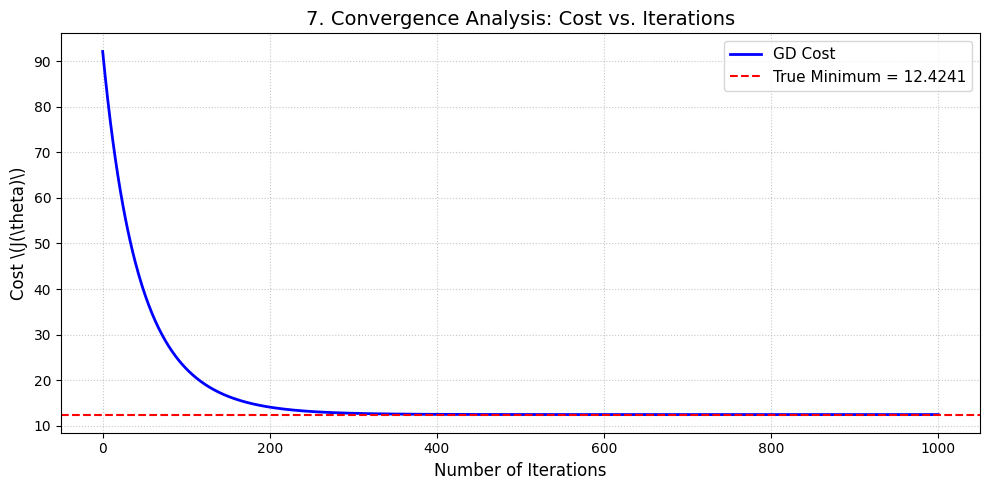

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. CHUẨN BỊ DỮ LIỆU & IN LOG CHI TIẾT
# ==========================================
# Lấy thông tin Theta từ Cell 4
t0_hist = theta_hist_gd[:, 0, 0]
t1_hist = theta_hist_gd[:, 1, 0]

# Tính nghiệm chính xác (để vẽ đường nằm ngang tham chiếu)
theta_analytical = np.linalg.inv(X_train_design.T @ X_train_design) @ (X_train_design.T @ y_train_vec)
cost_analytical = compute_cost(X_train_design, y_train_vec, theta_analytical)

# Lấy cost ban đầu (vòng 0) và nối vào mảng lịch sử
cost_init = compute_cost(X_train_design, y_train_vec, theta_start)
cost_hist_full = np.insert(cost_hist_gd, 0, cost_init)

# Tạo trục x từ 0 đến số vòng lặp
total_iters = len(cost_hist_full)
iterations = range(0, total_iters)

# --- IN LOG CHI TIẾT ---
print("="*55)
print("CHI TIẾT QUÁ TRÌNH HỘI TỤ")
print("="*55)
print("--- ĐIỂM BẮT ĐẦU (Vòng 0) ---")
print(f"  Theta_0 : {t0_hist[0]:.6f}")
print(f"  Theta_1 : {t1_hist[0]:.6f}")
print(f"  Cost J  : {cost_init:.6f}")

print(f"\n--- ĐIỂM KẾT THÚC (Vòng {total_iters - 1}) ---")
print(f"  Theta_0 : {t0_hist[-1]:.6f}")
print(f"  Theta_1 : {t1_hist[-1]:.6f}")
print(f"  Cost J  : {cost_hist_full[-1]:.6f}")

print("\n--- NGHIỆM CHÍNH XÁC (Analytical) ---")
print(f"  Theta_0 : {theta_analytical[0, 0]:.6f}")
print(f"  Theta_1 : {theta_analytical[1, 0]:.6f}")
print(f"  Cost J  : {cost_analytical:.6f}")

print("\n--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---")
print(f"  Delta Theta_0 : {abs(t0_hist[-1] - theta_analytical[0, 0]):.6f}")
print(f"  Delta Theta_1 : {abs(t1_hist[-1] - theta_analytical[1, 0]):.6f}")
print(f"  Delta Cost    : {abs(cost_hist_full[-1] - cost_analytical):.6f}")
print("="*55 + "\n")

# ==========================================
# 2. VẼ ĐỒ THỊ
# ==========================================
plt.figure(figsize=(10, 5))

# Vẽ đường Cost của Gradient Descent
plt.plot(iterations, cost_hist_full, color='blue', linewidth=2, label='GD Cost')

# Vẽ đường nằm ngang thể hiện mức Cost tối ưu (Normal Equation)
plt.axhline(y=cost_analytical, color='red', linestyle='--', linewidth=1.5, label=f'True Minimum = {cost_analytical:.4f}')

# Trang trí
plt.title('7. Convergence Analysis: Cost vs. Iterations', fontsize=14)
plt.xlabel('Number of Iterations', fontsize=12)
plt.ylabel(r'Cost \(J(\theta)\)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

plt.tight_layout()

# ==========================================
# 3. LƯU VÀ HIỂN THỊ
# ==========================================
# LƯU Ý: Luôn savefig TRƯỚC khi show
plt.savefig('convergence.png', dpi=300, bbox_inches='tight')
plt.show()

#8. Inference, model evaluation and residual analysis.


--- PHẦN 8: ĐÁNH GIÁ MÔ HÌNH VÀ SƠ ĐỒ SO SÁNH ---
 HỆ SỐ XÁC ĐỊNH (R^2 Score): 2.10% 
 SAI SỐ (MSE)               : 31.3520 


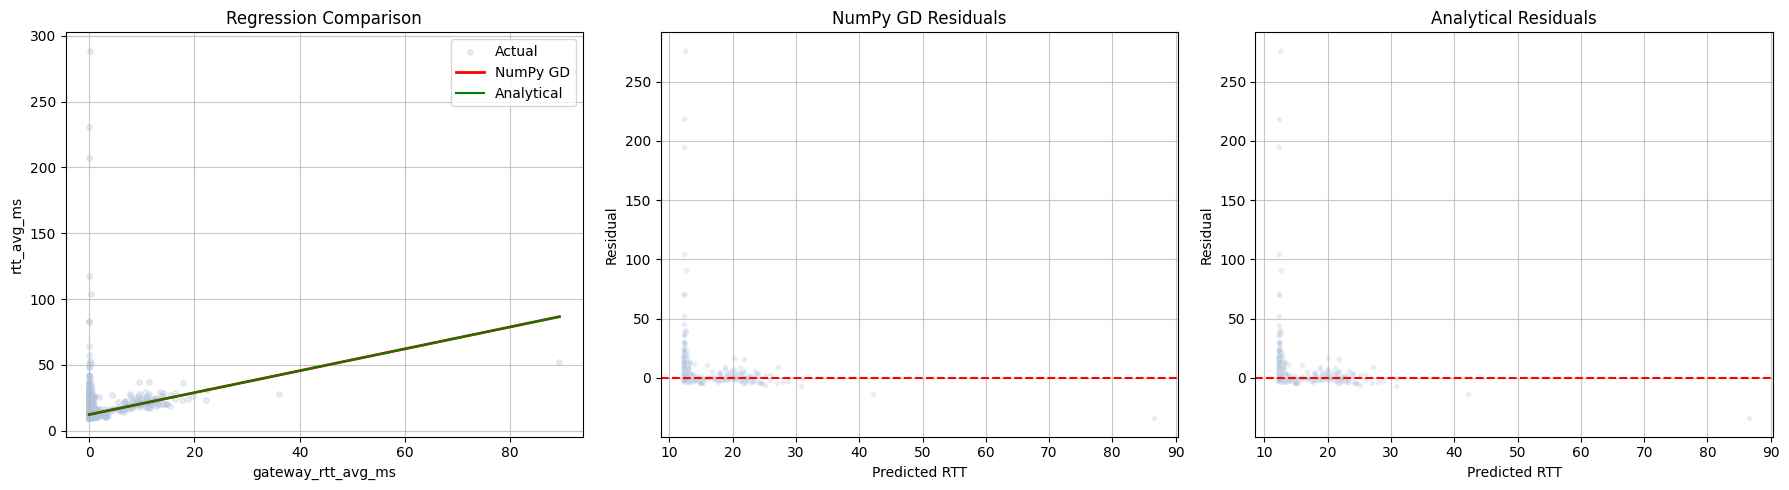

=> ĐÃ LƯU SƠ ĐỒ 3 BIỂU ĐỒ: regression_and_residuals.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("\n--- PHẦN 8: ĐÁNH GIÁ MÔ HÌNH VÀ SƠ ĐỒ SO SÁNH ---")

# --- 1. CHUẨN HÓA DỮ LIỆU ĐẦU VÀO CHO TẬP TEST ---
X_test_flat = np.array(X_test).astype(float).flatten()
y_test_flat = np.array(y_test).astype(float).flatten()

# Tạo ma trận thiết kế (thêm cột 1)
X_test_design = np.c_[np.ones((X_test_flat.shape[0], 1)), X_test_flat]

# --- 2. TẠO SẴN 2 BIẾN DỰ ĐOÁN (DẠNG 1 CHIỀU) ĐỂ PHẦN 9 XÀI KÉ MÀ KHÔNG BỊ LỖI ---
y_pred_gd = (X_test_design @ theta_gd.copy().astype(float).reshape(-1, 1)).flatten()
y_pred_analytical = (X_test_design @ theta_analytical.copy().astype(float).reshape(-1, 1)).flatten()

# --- 3. ĐÁNH GIÁ CHỈ SỐ BẢN GD (CHO RIÊNG PHẦN 8) ---
mse = mean_squared_error(y_test_flat, y_pred_gd)
r2 = r2_score(y_test_flat, y_pred_gd)

print("="*40)
print(f" HỆ SỐ XÁC ĐỊNH (R^2 Score): {r2*100:.2f}% ")
print(f" SAI SỐ (MSE)               : {mse:.4f} ")
print("="*40)

# --- 4. TÍNH PHẦN DƯ CHO CẢ 2 ĐỂ VẼ BIỂU ĐỒ ---
residuals_gd = y_test_flat - y_pred_gd
residuals_analytical = y_test_flat - y_pred_analytical

# --- 5. VẼ 3 BIỂU ĐỒ ĐẶT CẠNH NHAU (1 HÀNG, 3 CỘT) Y HỆT ẢNH ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Biểu đồ 1: Regression Comparison (Đường hồi quy so với thực tế)
axes[0].scatter(X_test_flat, y_test_flat, alpha=0.3, s=15, color='lightsteelblue', label='Actual')
# Sắp xếp X_test để vẽ đường thẳng hồi quy mượt mà, không bị rối nét
sorted_idx = np.argsort(X_test_flat)
axes[0].plot(X_test_flat[sorted_idx], y_pred_gd[sorted_idx], color='red', linewidth=2, label='NumPy GD')
axes[0].plot(X_test_flat[sorted_idx], y_pred_analytical[sorted_idx], color='green', linewidth=1.5, label='Analytical')
axes[0].set_title('Regression Comparison')
axes[0].set_xlabel('gateway_rtt_avg_ms')
axes[0].set_ylabel('rtt_avg_ms')
axes[0].legend()
axes[0].grid(True, linestyle='-', alpha=0.7)

# Biểu đồ 2: NumPy GD Residuals
sns.scatterplot(ax=axes[1], x=y_pred_gd, y=residuals_gd, alpha=0.3, s=15, color='lightsteelblue')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('NumPy GD Residuals')
axes[1].set_xlabel('Predicted RTT')
axes[1].set_ylabel('Residual')
axes[1].grid(True, linestyle='-', alpha=0.7)

# Biểu đồ 3: Analytical Residuals
sns.scatterplot(ax=axes[2], x=y_pred_analytical, y=residuals_analytical, alpha=0.3, s=15, color='lightsteelblue')
axes[2].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[2].set_title('Analytical Residuals')
axes[2].set_xlabel('Predicted RTT')
axes[2].set_ylabel('Residual')
axes[2].grid(True, linestyle='-', alpha=0.7)

plt.tight_layout()
plt.savefig('regression_and_residuals.png', dpi=300)
plt.show()
print("=> ĐÃ LƯU SƠ ĐỒ 3 BIỂU ĐỒ: regression_and_residuals.png")

In [ ]:
import numpy as np

# Lấy trọng số theta đã huấn luyện từ các bước trước
try:
    theta0 = theta_gd[0, 0] if hasattr(theta_gd, 'shape') and len(theta_gd.shape) > 1 else theta_gd[0]
    theta1 = theta_gd[1, 0] if hasattr(theta_gd, 'shape') and len(theta_gd.shape) > 1 else theta_gd[1]
except NameError:
    # Giá trị dự phòng (fallback) nếu mảng theta bị rỗng
    theta0 = 12.31318397
    theta1 = 0.83144724

print("=== HỆ THỐNG DỰ ĐOÁN ĐỘ TRỄ MẠNG (RTT) ===")
print(f"Mô hình hiện tại: y = {theta0:.6f} + {theta1:.6f} * x\n")

# --- SỬA LỖI TREO MÁY: Thay thế lệnh input() bằng biến gán cứng ---
# Anh có thể thay đổi số 25.0 bên dưới thành bất kỳ con số Gateway nào anh muốn thử nghiệm
x_val = 25.0

# Áp dụng phương trình hồi quy tuyến tính: y = theta_0 + theta_1 * x
y_predict_demo = theta0 + theta1 * x_val

print("--- KẾT QUẢ DỰ ĐOÁN DEMO ---")
print(f"Độ trễ Gateway đầu vào (x) : {x_val:.4f} ms")
print(f"Độ trễ RTT máy chủ dự đoán (y): {y_predict_demo:.4f} ms")
print("============================================")

=== HỆ THỐNG DỰ ĐOÁN ĐỘ TRỄ MẠNG (RTT) ===
Mô hình hiện tại: y = 12.313184 + 0.831447 * x

--- KẾT QUẢ DỰ ĐOÁN DEMO ---
Độ trễ Gateway đầu vào (x) : 25.0000 ms
Độ trễ RTT máy chủ dự đoán (y): 33.0994 ms


#9. Comparison with library implementation

In [ ]:

# =========================================================
# CELL 21 - QUESTION 9
# COMPARISON WITH LIBRARY IMPLEMENTATION
# =========================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# =========================================================
# 1. EXPERIMENT CONFIGURATION
# =========================================================

INPUT_FEATURE = "gateway_rtt_avg_ms"
TARGET_FEATURE = "rtt_avg_ms"

LEARNING_RATE = 0.01
NUM_ITERATIONS = 1000
N_REPEATS = 7

# Dữ liệu từ Cell 19
# X_train, X_test, y_train, y_test
# X_train_matrix, X_test_matrix
# theta_gd từ Cell 11

X_tr = np.asarray(X_train, dtype=float).reshape(-1, 1)
X_te = np.asarray(X_test, dtype=float).reshape(-1, 1)
y_tr = np.asarray(y_train, dtype=float).reshape(-1, 1)
y_te = np.asarray(y_test, dtype=float).reshape(-1, 1)

A_train = np.column_stack([
    np.ones(len(X_tr)),
    X_tr.ravel()
])

A_test = np.column_stack([
    np.ones(len(X_te)),
    X_te.ravel()
])

# Kiểm tra dữ liệu và cấu trúc
np.testing.assert_allclose(A_train, X_train_matrix)
np.testing.assert_allclose(A_test, X_test_matrix)
np.testing.assert_allclose(A_train, X_train_design)
np.testing.assert_allclose(y_tr, y_train_vec)

print("=" * 65)
print("EXPERIMENT CONFIGURATION")
print("=" * 65)
print("Input feature :", INPUT_FEATURE)
print("Target feature:", TARGET_FEATURE)
print("Train samples :", len(X_tr))
print("Test samples  :", len(X_te))
print("GD iterations:", NUM_ITERATIONS)
print("GD learning rate:", LEARNING_RATE)
print("Benchmark repeats:", N_REPEATS)

# =========================================================
# 2. NUMPY GRADIENT DESCENT - BASELINE
# =========================================================

def fit_numpy_gd(
    X_design,
    y,
    learning_rate=0.01,
    num_iterations=1000
):
    """
    Full-batch Gradient Descent.
    Objective: J(theta) = (1/2n) * sum((X@theta-y)^2)

    Không ghi lịch sử cost để thời gian đo
    phản ánh riêng quá trình tối ưu.
    """

    n_samples, n_features = X_design.shape

    theta = np.zeros((n_features, 1), dtype=float)

    for _ in range(num_iterations):
        errors = X_design @ theta - y
        gradient = (X_design.T @ errors) / n_samples
        theta = theta - learning_rate * gradient

    return theta


# =========================================================
# 3. COMPUTATIONAL EFFICIENCY BENCHMARK
# =========================================================

numpy_times = []
sklearn_times = []

# Warm-up: tránh tính chi phí khởi động ban đầu
_ = fit_numpy_gd(
    A_train, y_tr,
    learning_rate=LEARNING_RATE,
    num_iterations=NUM_ITERATIONS
)

warmup_model = LinearRegression()
warmup_model.fit(X_tr, y_tr.ravel())

# Mỗi lần lặp huấn luyện lại từ đầu
for repeat in range(N_REPEATS):

    # ----- NumPy GD (Baseline) -----
    start = time.perf_counter()

    theta_numpy = fit_numpy_gd(
        A_train,
        y_tr,
        learning_rate=LEARNING_RATE,
        num_iterations=NUM_ITERATIONS
    )

    elapsed_numpy = time.perf_counter() - start
    numpy_times.append(elapsed_numpy)

    # ----- Scikit-learn Linear Regression -----
    start = time.perf_counter()

    sklearn_model = LinearRegression()
    sklearn_model.fit(X_tr, y_tr.ravel())

    elapsed_sklearn = time.perf_counter() - start
    sklearn_times.append(elapsed_sklearn)

# Thời gian trung vị
time_numpy_gd = float(np.median(numpy_times))
time_sklearn = float(np.median(sklearn_times))

# Kiểm tra NumPy GD khớp Cell 11
np.testing.assert_allclose(
    theta_numpy,
    np.asarray(theta_gd).reshape(-1, 1),
    rtol=1e-8,
    atol=1e-8,
    err_msg="GD benchmark không khớp kết quả Cell 11."
)

# =========================================================
# 4. INFERENCE PERFORMANCE
# =========================================================

# NumPy GD
y_pred_gd = A_test @ theta_numpy

# Scikit-learn
y_pred_sklearn = sklearn_model.predict(
    X_te
).reshape(-1, 1)

mse_gd = mean_squared_error(y_te, y_pred_gd)
r2_gd = r2_score(y_te, y_pred_gd)

mse_sklearn = mean_squared_error(
    y_te, y_pred_sklearn
)
r2_sklearn = r2_score(
    y_te, y_pred_sklearn
)

# Parameters
theta0_gd = float(theta_numpy[0, 0])
theta1_gd = float(theta_numpy[1, 0])

theta0_sklearn = float(sklearn_model.intercept_)
theta1_sklearn = float(sklearn_model.coef_[0])

# Difference between predictions
prediction_diff_mean = float(
    np.mean(np.abs(y_pred_sklearn - y_pred_gd))
)

# Loss verification
# J(theta) = 1/(2n) * SSE
# MSE = 1/n * SSE = 2J(theta)
cost_gd_test = mse_gd / 2

# =========================================================
# 5. RESULTS TABLE
# =========================================================

comparison_df = pd.DataFrame({
    "Metric": [
        "Intercept (theta_0)",
        "Slope (theta_1)",
        "Test MSE (ms^2)",
        "Test R2",
        "Median training time (s)"
    ],
    "NumPy GD (Baseline)": [
        theta0_gd,
        theta1_gd,
        mse_gd,
        r2_gd,
        time_numpy_gd
    ],
    "Scikit-learn Linear Regression": [
        theta0_sklearn,
        theta1_sklearn,
        mse_sklearn,
        r2_sklearn,
        time_sklearn
    ]
})

print("\n" + "=" * 75)
print("MODEL COMPARISON RESULTS")
print("=" * 75)
print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

# =========================================================
# 6. LOSS FUNCTION VERIFICATION
# =========================================================

print("\n" + "=" * 65)
print("LOSS FUNCTION VERIFICATION")
print("=" * 65)

print(f"NumPy GD Test Cost J : {cost_gd_test:.8f}")
print(f"NumPy GD Test MSE    : {mse_gd:.8f}")
print(f"MSE / J              : {mse_gd/cost_gd_test:.4f}")

print("\nMSE = 2 * J(theta)")
print("Hai hàm có cùng nghiệm tối ưu.")

# =========================================================
# 7. COMPUTATIONAL EFFICIENCY RESULTS
# =========================================================

print("\n" + "=" * 65)
print("COMPUTATIONAL EFFICIENCY")
print("=" * 65)

print(f"NumPy GD median time    : {time_numpy_gd:.6f} s")
print(f"Scikit-learn median time: {time_sklearn:.6f} s")

if time_sklearn > 0:
    speed_ratio = time_numpy_gd / time_sklearn
    print(f"Training time ratio     : {speed_ratio:.2f}x")

print("\nIndividual measurements:")
for i, (t_np, t_sk) in enumerate(
    zip(numpy_times, sklearn_times), start=1
):
    print(
        f"Run {i}: "
        f"NumPy={t_np:.6f}s | "
        f"Scikit-learn={t_sk:.6f}s"
    )

print("\nMean absolute prediction difference:")
print(f"{prediction_diff_mean:.6f} ms")

# =========================================================
# 8. REGRESSION VISUALIZATION
# =========================================================

plt.figure(figsize=(11, 6))

plt.scatter(
    X_te.ravel(),
    y_te.ravel(),
    color="gray",
    alpha=0.25,
    s=10,
    label="Actual Test Data"
)

x_line = np.linspace(
    X_te.min(),
    X_te.max(),
    200
).reshape(-1, 1)

A_line = np.column_stack([
    np.ones(len(x_line)),
    x_line.ravel()
])

y_line_gd = A_line @ theta_numpy
y_line_sklearn = sklearn_model.predict(x_line)

plt.plot(
    x_line.ravel(),
    y_line_gd.ravel(),
    color="orange",
    linewidth=2.5,
    linestyle="--",
    label="NumPy GD (Baseline)"
)

plt.plot(
    x_line.ravel(),
    y_line_sklearn.ravel(),
    color="red",
    linewidth=2,
    label="Scikit-learn Linear Regression"
)

plt.title(
    "Univariate Linear Regression Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("gateway_rtt_avg_ms (ms)")
plt.ylabel("rtt_avg_ms (ms)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


NameError: name 'X_train_matrix' is not defined

##10 Model improvement

In [ ]:

# =========================================================
# CELL 25 - QUESTION 10: MODEL IMPROVEMENT
# =========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score
from datasets import load_dataset

try:
    from xgboost import XGBRegressor
except ImportError:
    %pip install -q xgboost
    from xgboost import XGBRegressor

# =========================================================
# 1. MULTIVARIATE DATA PREPARATION
# =========================================================

dataset_full = load_dataset("ezharjan/LocalNetDynamics")
df_raw = dataset_full[
    list(dataset_full.keys())[0]
].to_pandas()

features_multivariate = [
    "gateway_rtt_avg_ms",
    "tcp_connect_median_ms",
    "dns_resolve_ms",
    "dns_recursive_ms"
]

target_col_name = "rtt_avg_ms"

# Làm sạch dữ liệu
clean_multi_data = (
    df_raw[features_multivariate + [target_col_name]]
    .dropna()
    .copy()
)

X_multi_clean = clean_multi_data[features_multivariate]
y_multi_clean = clean_multi_data[target_col_name]

# 80% train, 20% test
X_train_m, X_test_m, y_train_m, y_test_m = (
    train_test_split(
        X_multi_clean,
        y_multi_clean,
        test_size=0.2,
        random_state=42
    )
)

print("=" * 65)
print("MULTIVARIATE DATA PREPARATION")
print("=" * 65)
print("Input features:", features_multivariate)
print("Target:", target_col_name)
print("Total samples:", len(clean_multi_data))
print("Train samples:", len(X_train_m))
print("Test samples:", len(X_test_m))

# =========================================================
# 2. FEATURE SCALING FOR NUMPY GD WITH MOMENTUM
# =========================================================

# Thống kê chỉ từ train set
train_mean = X_train_m.mean()
train_std = X_train_m.std()

X_train_m_scaled = (
    X_train_m - train_mean
) / (train_std + 1e-8)

X_test_m_scaled = (
    X_test_m - train_mean
) / (train_std + 1e-8)

# Design matrix with intercept
X_train_m_design = np.column_stack([
    np.ones(len(X_train_m_scaled)),
    X_train_m_scaled.to_numpy()
])

X_test_m_design = np.column_stack([
    np.ones(len(X_test_m_scaled)),
    X_test_m_scaled.to_numpy()
])

y_train_m_vec = y_train_m.to_numpy().reshape(-1, 1)
y_test_m_vec = y_test_m.to_numpy().reshape(-1, 1)

# =========================================================
# 3. NUMPY GRADIENT DESCENT WITH MOMENTUM
# =========================================================

def gradient_descent_momentum(
    X,
    y,
    lr=0.01,
    beta=0.9,
    num_iters=1000
):
    n_samples, n_features = X.shape

    theta = np.zeros((n_features, 1))
    velocity = np.zeros((n_features, 1))

    for _ in range(num_iters):
        predictions = X @ theta
        errors = predictions - y

        gradient = (X.T @ errors) / n_samples

        velocity = beta * velocity + lr * gradient
        theta = theta - velocity

    return theta

# =========================================================
# 4. BASELINE REFERENCE - UNIVARIATE
# =========================================================

# Sử dụng kết quả đã tính trong Cell 21
mse_baseline = mean_squared_error(y_test, y_pred_gd)
r2_baseline = r2_score(y_test, y_pred_gd)

print("\n" + "=" * 65)
print("BASELINE REFERENCE (UNIVARIATE)")
print("=" * 65)
print("Model: NumPy GD (Baseline)")
print("Input: gateway_rtt_avg_ms")
print("Output: rtt_avg_ms")
print(f"Test MSE: {mse_baseline:.6f}")
print(f"Test R2 : {r2_baseline:.6f}")

# =========================================================
# 5. TRAINING IMPROVEMENT MODELS
# =========================================================

results_improvement = []

def add_result(name, actual, predicted):
    results_improvement.append({
        "Model": name,
        "Test MSE": mean_squared_error(actual, predicted),
        "Test R2": r2_score(actual, predicted)
    })

# ----- Model 1: Scikit-learn Linear Regression -----
model_lr = LinearRegression()
model_lr.fit(X_train_m, y_train_m)

y_pred_lr = model_lr.predict(X_test_m)

add_result(
    "Scikit-learn LR (Multivariate)",
    y_test_m, y_pred_lr
)

# ----- Model 2: Lasso Regression (L1) -----
model_lasso = Lasso(
    alpha=0.1,
    random_state=42
)
model_lasso.fit(X_train_m, y_train_m)

y_pred_lasso = model_lasso.predict(X_test_m)

add_result(
    "Lasso Regression (L1)",
    y_test_m, y_pred_lasso
)

# ----- Model 3: Ridge Regression (L2) -----
model_ridge = Ridge(alpha=1.0)
model_ridge.fit(X_train_m, y_train_m)

y_pred_ridge = model_ridge.predict(X_test_m)

add_result(
    "Ridge Regression (L2)",
    y_test_m, y_pred_ridge
)

# ----- Model 4: Decision Tree Regressor -----
model_dt = DecisionTreeRegressor(
    max_depth=8,
    min_samples_split=10,
    random_state=42
)

model_dt.fit(X_train_m, y_train_m)
y_pred_dt = model_dt.predict(X_test_m)

add_result(
    "Decision Tree Regressor",
    y_test_m, y_pred_dt
)

# ----- Model 5: XGBoost Regressor -----
model_xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.08,
    max_depth=6,
    random_state=42
)

model_xgb.fit(X_train_m, y_train_m)
y_pred_xgb = model_xgb.predict(X_test_m)

add_result(
    "XGBoost Regressor",
    y_test_m, y_pred_xgb
)

# ----- Model 6: AdaBoost Regressor -----
model_ada = AdaBoostRegressor(
    n_estimators=50,
    learning_rate=0.1,
    random_state=42
)

model_ada.fit(X_train_m, y_train_m)
y_pred_ada = model_ada.predict(X_test_m)

add_result(
    "AdaBoost Regressor",
    y_test_m, y_pred_ada
)

# ----- Model 7: NumPy GD with Momentum -----
theta_momentum = gradient_descent_momentum(
    X_train_m_design,
    y_train_m_vec,
    lr=0.01,
    beta=0.9,
    num_iters=1000
)

y_pred_momentum = X_test_m_design @ theta_momentum

add_result(
    "NumPy GD with Momentum",
    y_test_m_vec,
    y_pred_momentum
)

# =========================================================
# 6. HYPERPARAMETER SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("MODEL HYPERPARAMETERS")
print("=" * 75)

print("Baseline - NumPy GD (Univariate):")
print("  lr=0.01, iterations=1000")

print("\nImprovement Models:")
print("1. Scikit-learn LR (Multivariate): OLS, intercept=True")
print("2. Lasso Regression (L1): alpha=0.1")
print("3. Ridge Regression (L2): alpha=1.0")
print("4. Decision Tree: max_depth=8, min_samples_split=10")
print("5. XGBoost: n_estimators=100, lr=0.08, max_depth=6")
print("6. AdaBoost: n_estimators=50, lr=0.1")
print("7. NumPy GD with Momentum: lr=0.01, beta=0.9, iterations=1000")

# =========================================================
# 7. IMPROVEMENT MODEL RESULTS
# =========================================================

df_results = pd.DataFrame(results_improvement)

df_results = df_results.sort_values(
    by="Test MSE",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MULTIVARIATE IMPROVEMENT MODEL COMPARISON")
print("=" * 75)

print(
    df_results.to_string(
        index=False,
        formatters={
            "Test MSE": "{:.4f}".format,
            "Test R2": "{:.4f}".format
        }
    )
)

# Best model among multivariate models
best_model = df_results.iloc[0]

print("\nBest Improvement Model:")
print("Model:", best_model["Model"])
print(f"Test MSE: {best_model['Test MSE']:.4f}")
print(f"Test R2 : {best_model['Test R2']:.4f}")

print("\nNote: Univariate baseline and multivariate models")
print("use separately prepared test sets; their MSE values")
print("are not directly compared as a controlled experiment.")


In [ ]:
# =========================================================
# CELL 25A - UNIVARIATE MODELS ON THE SAME Q10 TEST SPLIT
# Insert directly AFTER the original Cell 25.
# Does not modify the original Q9 results.
# =========================================================
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

UNI_FEATURE = "gateway_rtt_avg_ms"
X_tr_uni = X_train_m[[UNI_FEATURE]].to_numpy(dtype=float)
X_te_uni = X_test_m[[UNI_FEATURE]].to_numpy(dtype=float)
y_tr_uni = y_train_m.to_numpy(dtype=float).reshape(-1, 1)
y_te_uni = y_test_m.to_numpy(dtype=float).reshape(-1, 1)

# The same full-batch GD configuration as Q9: lr=0.01, 1000 steps.
A_tr_uni = np.column_stack((np.ones(len(X_tr_uni)), X_tr_uni))
A_te_uni = np.column_stack((np.ones(len(X_te_uni)), X_te_uni))
theta_uni_q10 = np.zeros((2, 1))
for _ in range(1000):
    grad = A_tr_uni.T @ (A_tr_uni @ theta_uni_q10 - y_tr_uni) / len(y_tr_uni)
    theta_uni_q10 -= 0.01 * grad
pred_uni_gd_q10 = A_te_uni @ theta_uni_q10

# OLS univariate from scikit-learn, on exactly the SAME test rows.
model_lr_uni_q10 = LinearRegression()
model_lr_uni_q10.fit(X_tr_uni, y_tr_uni.ravel())
pred_uni_sklearn_q10 = model_lr_uni_q10.predict(X_te_uni)

extra_rows = pd.DataFrame([
    {
        "Model": "NumPy GD (Univariate Baseline)",
        "Test MSE": mean_squared_error(y_te_uni, pred_uni_gd_q10),
        "Test R2": r2_score(y_te_uni, pred_uni_gd_q10)
    },
    {
        "Model": "Scikit-learn LR (Univariate)",
        "Test MSE": mean_squared_error(y_te_uni, pred_uni_sklearn_q10),
        "Test R2": r2_score(y_te_uni, pred_uni_sklearn_q10)
    }
])

# Original Cell 25 stores only 7 multivariate models.
# Add the two univariate rows to create a fair nine-model comparison.
df_results_9 = pd.concat([df_results, extra_rows], ignore_index=True)
df_results_9 = df_results_9.sort_values("Test MSE").reset_index(drop=True)
print("\nQUESTION 10 — FAIR COMPARISON: 9 MODELS, SAME TEST SET")
print("Train:", len(X_train_m), "| Test:", len(X_test_m))
print(df_results_9.to_string(index=False, float_format=lambda z: f"{z:.6f}"))
print("\nBest model:", df_results_9.iloc[0]["Model"])
print("NOTE: Q9's earlier univariate numbers used a different cleaning/split;")
print("the two new univariate rows are refitted on the Q10 split.")


In [ ]:

# =========================================================
# CELL 26 (REPLACE) - PERFORMANCE BY TRAINING DATA SIZE
# Nine models; same validation rows; six nested training sizes.
# Outputs: result tables + grouped horizontal bar chart.
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

FEATURES_MULTI = [
    "gateway_rtt_avg_ms", "tcp_connect_median_ms",
    "dns_resolve_ms", "dns_recursive_ms"
]
FEATURE_BASELINE = "gateway_rtt_avg_ms"
TRAIN_FRACTIONS = np.array([0.10, 0.20, 0.40, 0.60, 0.80, 1.00])
RANDOM_STATE, GD_LR, GD_ITERATIONS, MOMENTUM_BETA = 42, 0.01, 1000, 0.9

MODEL_NAMES = [
    "NumPy GD (Univariate Baseline)",
    "Scikit-learn LR (Univariate)",
    "Scikit-learn LR (Multivariate)",
    "Lasso Regression (L1)",
    "Ridge Regression (L2)",
    "Decision Tree Regressor",
    "XGBoost Regressor",
    "AdaBoost Regressor",
    "NumPy GD with Momentum"
]

# =========================================================
# 1. PREPARE TRAINING POOL AND FIXED VALIDATION
# =========================================================

# Split ONLY the training data from Cell 25.
# The final test set is untouched.
X_pool, X_val, y_pool, y_val = train_test_split(
    X_train_m[FEATURES_MULTI], y_train_m,
    test_size=0.20, random_state=RANDOM_STATE
)

permutation = np.random.default_rng(RANDOM_STATE).permutation(
    len(X_pool)
)

train_sizes = np.array([
    max(2, int(len(X_pool) * frac))
    for frac in TRAIN_FRACTIONS
])


# =========================================================
# 2. NUMPY GRADIENT DESCENT IMPLEMENTATION
# =========================================================

# No scaling for univariate GD (matching Q9).
# Scaling is applied ONLY to multivariate GD + Momentum.

def fit_gd_fraction(X_sub, y_sub, X_predict, *, momentum=False):
    X_sub = np.asarray(X_sub, dtype=float)
    X_predict = np.asarray(X_predict, dtype=float)
    y = np.asarray(y_sub, dtype=float).reshape(-1, 1)

    if momentum:
        mu = X_sub.mean(axis=0)
        sigma = X_sub.std(axis=0, ddof=1) + 1e-8

        X_predict = (X_predict - mu) / sigma
        X_sub = (X_sub - mu) / sigma

    A = np.column_stack((np.ones(len(X_sub)), X_sub))
    A_pred = np.column_stack(
        (np.ones(len(X_predict)), X_predict)
    )

    theta = np.zeros((A.shape[1], 1))
    velocity = np.zeros_like(theta)

    for _ in range(GD_ITERATIONS):
        gradient = A.T @ (A @ theta - y) / len(y)

        if momentum:
            velocity = MOMENTUM_BETA * velocity + GD_LR * gradient
            theta -= velocity
        else:
            theta -= GD_LR * gradient

    return (A @ theta).ravel(), (A_pred @ theta).ravel()


# =========================================================
# 3. DEFINE MULTIVARIATE MODELS
# =========================================================

def multi_models():
    return {
        "Scikit-learn LR (Multivariate)": LinearRegression(),

        "Lasso Regression (L1)": Lasso(
            alpha=0.1,
            max_iter=10000,
            random_state=RANDOM_STATE
        ),

        "Ridge Regression (L2)": Ridge(alpha=1.0),

        "Decision Tree Regressor": DecisionTreeRegressor(
            max_depth=8,
            min_samples_split=10,
            random_state=RANDOM_STATE
        ),

        "XGBoost Regressor": XGBRegressor(
            n_estimators=100,
            learning_rate=0.08,
            max_depth=6,
            random_state=RANDOM_STATE
        ),

        "AdaBoost Regressor": AdaBoostRegressor(
            n_estimators=50,
            learning_rate=0.1,
            random_state=RANDOM_STATE
        )
    }


# =========================================================
# 4. TRAIN NINE MODELS AT SIX TRAINING SIZES
# =========================================================

records = []

def record(name, frac, n, y_train, p_train, y_valid, p_valid):
    records.append({
        "Model": name,
        "Train Fraction": frac,
        "Train Samples": n,
        "Train MSE": mean_squared_error(y_train, p_train),
        "Validation MSE": mean_squared_error(y_valid, p_valid)
    })


for frac, n in zip(TRAIN_FRACTIONS, train_sizes):

    idx = permutation[:n]  # Nested, reproducible subsets

    X_sub = X_pool.iloc[idx]
    y_sub = y_pool.iloc[idx]

    X_sub_uni = X_sub[[FEATURE_BASELINE]]
    X_val_uni = X_val[[FEATURE_BASELINE]]

    # Model 1: NumPy GD univariate
    tr, va = fit_gd_fraction(
        X_sub_uni, y_sub, X_val_uni
    )
    record(
        MODEL_NAMES[0], frac, n, y_sub, tr, y_val, va
    )

    # Model 2: Scikit-learn OLS univariate
    uni_ols = LinearRegression().fit(X_sub_uni, y_sub)

    record(
        MODEL_NAMES[1], frac, n,
        y_sub, uni_ols.predict(X_sub_uni),
        y_val, uni_ols.predict(X_val_uni)
    )

    # Models 3-8: Multivariate models
    for name, model in multi_models().items():
        model.fit(X_sub, y_sub)

        record(
            name, frac, n,
            y_sub, model.predict(X_sub),
            y_val, model.predict(X_val)
        )

    # Model 9: NumPy GD with Momentum, multivariate
    tr, va = fit_gd_fraction(
        X_sub, y_sub, X_val, momentum=True
    )

    record(
        MODEL_NAMES[-1], frac, n,
        y_sub, tr, y_val, va
    )

    print(
        f"Completed {frac:.0%} "
        f"({n:,} train samples): 9 models"
    )


# =========================================================
# 5. BUILD AND DISPLAY RESULT TABLES
# =========================================================

# Keep variable name for compatibility with other cells.
learning_curve_results = pd.DataFrame(records)

assert len(learning_curve_results) == (
    len(TRAIN_FRACTIONS) * len(MODEL_NAMES)
)

print("\nTRAINING-SIZE PERFORMANCE COMPARISON — 9 MODELS")
print(
    f"Training pool: {len(X_pool):,} | "
    f"Fixed validation: {len(X_val):,}"
)
print(f"Final test samples not used: {len(X_test_m):,}")

for frac, n in zip(TRAIN_FRACTIONS, train_sizes):

    table = learning_curve_results.loc[
        np.isclose(
            learning_curve_results["Train Fraction"], frac
        ),
        ["Model", "Train MSE", "Validation MSE"]
    ].sort_values(
        "Validation MSE"
    ).reset_index(drop=True)

    display(Markdown(
        f"### {frac:.0%} training data — {n:,} samples"
    ))

    display(
        table.style.format({
            "Train MSE": "{:.4f}",
            "Validation MSE": "{:.4f}"
        }).hide(axis="index")
    )


# =========================================================
# 6. BEST VALIDATION MODEL AT 100% TRAINING DATA
# =========================================================

full = learning_curve_results[
    np.isclose(
        learning_curve_results["Train Fraction"], 1.0
    )
].sort_values("Validation MSE")

print(
    "\nBest validation model at 100%:",
    full.iloc[0]["Model"]
)
print(
    "Validation MSE:",
    round(full.iloc[0]["Validation MSE"], 4)
)


# =========================================================
# 7. NEW: TRAINING-SIZE PERFORMANCE BAR CHART
# =========================================================

# Uses calculated values from learning_curve_results.
# No manually entered MSE values.

# Short display names for better chart readability.
# Full model names are preserved in the tables.
SHORT_NAMES = {
    "NumPy GD (Univariate Baseline)": "NumPy GD (Uni)",
    "Scikit-learn LR (Univariate)": "Sklearn LR (Uni)",
    "Scikit-learn LR (Multivariate)": "Sklearn LR (Multi)",
    "Lasso Regression (L1)": "Lasso (L1)",
    "Ridge Regression (L2)": "Ridge (L2)",
    "Decision Tree Regressor": "Decision Tree",
    "XGBoost Regressor": "XGBoost",
    "AdaBoost Regressor": "AdaBoost",
    "NumPy GD with Momentum": "GD + Momentum"
}

fig, axes = plt.subplots(
    3, 2,
    figsize=(22, 22)
)

axes = axes.flatten()

bar_height = 0.36

# Shared X-axis limit to make comparisons consistent.
max_mse = learning_curve_results[
    ["Train MSE", "Validation MSE"]
].to_numpy().max()

x_limit = max_mse * 1.22

for ax, frac, n in zip(
    axes, TRAIN_FRACTIONS, train_sizes
):

    # Select results for the corresponding training size.
    subset = learning_curve_results.loc[
        np.isclose(
            learning_curve_results["Train Fraction"], frac
        )
    ].copy()

    # Sort models by Validation MSE, ascending.
    subset = subset.sort_values(
        "Validation MSE",
        ascending=True
    ).reset_index(drop=True)

    labels = [
        SHORT_NAMES.get(name, name)
        for name in subset["Model"]
    ]

    positions = np.arange(len(subset))

    # Train MSE bars
    bars_train = ax.barh(
        positions - bar_height / 2,
        subset["Train MSE"],
        height=bar_height,
        label="Train MSE"
    )

    # Validation MSE bars
    bars_val = ax.barh(
        positions + bar_height / 2,
        subset["Validation MSE"],
        height=bar_height,
        label="Validation MSE"
    )

    # Value labels
    ax.bar_label(
        bars_train,
        fmt="%.2f",
        padding=3,
        fontsize=8
    )

    ax.bar_label(
        bars_val,
        fmt="%.2f",
        padding=3,
        fontsize=8
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=10)

    # Best validation model displayed first.
    ax.invert_yaxis()

    ax.set_xlim(0, x_limit)

    ax.set_title(
        f"{frac:.0%} Training Data — {n:,} Samples",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Mean Squared Error (MSE)", fontsize=10)

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)


# Common legend for all six charts.
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.952),
    ncol=2,
    fontsize=12,
    frameon=False
)

fig.suptitle(
    "TRAINING-SIZE PERFORMANCE COMPARISON — 9 MODELS\n"
    f"Training Pool: {len(X_pool):,} | "
    f"Fixed Validation: {len(X_val):,} | "
    f"Final Test Not Used: {len(X_test_m):,}",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    left=0.13,
    right=0.98,
    top=0.91,
    bottom=0.05,
    wspace=0.40,
    hspace=0.32
)

# Export high-resolution figure for LaTeX / Overleaf.
chart_filename = (
    "Task10_Training_Size_Performance_Bar_Chart_9_Models.png"
)

fig.savefig(
    chart_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nBar chart saved: {chart_filename}")


In [ ]:
# =========================================================
# CELL 28 (NEW) - CONVERGENCE / TRAINING-STAGE CURVES
# 5 iterative models: GD, GD+Momentum, XGBoost, AdaBoost,
# and reconstructed coordinate-descent passes of Lasso.
# All models use SAME train pool and validation rows (Cell 26).
# Never evaluate final test data while building these curves.
# =========================================================
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import AdaBoostRegressor
from xgboost import XGBRegressor

X_tr_all = X_pool[FEATURES_MULTI].to_numpy(dtype=float)
X_va_all = X_val[FEATURES_MULTI].to_numpy(dtype=float)
y_tr_all = y_pool.to_numpy(dtype=float).ravel()
y_va_all = y_val.to_numpy(dtype=float).ravel()
X_tr_uni = X_pool[[FEATURE_BASELINE]].to_numpy(dtype=float)
X_va_uni = X_val[[FEATURE_BASELINE]].to_numpy(dtype=float)


def gd_history(X_tr, y_tr, X_va, y_va, *, lr=0.01, n_iter=1000,
               beta=None, standardize=False):
    """Full-batch GD. Log BOTH train and validation MSE per iteration."""
    if standardize:
        mu = X_tr.mean(axis=0)
        std = X_tr.std(axis=0, ddof=1) + 1e-8
        X_va = (X_va - mu) / std
        X_tr = (X_tr - mu) / std
    A_tr = np.column_stack((np.ones(len(X_tr)), X_tr))
    A_va = np.column_stack((np.ones(len(X_va)), X_va))
    theta = np.zeros((A_tr.shape[1], 1))
    velocity = np.zeros_like(theta)
    y_tr = y_tr.reshape(-1, 1)
    train_mse, valid_mse = [], []

    for _ in range(n_iter):
        residual = A_tr @ theta - y_tr
        grad = A_tr.T @ residual / len(y_tr)
        if beta is None:
            theta -= lr * grad
        else:
            velocity = beta * velocity + lr * grad
            theta -= velocity
        train_mse.append(float(np.mean((A_tr @ theta - y_tr) ** 2)))
        valid_mse.append(float(np.mean((A_va @ theta - y_va.reshape(-1, 1)) ** 2)))
    return np.asarray(train_mse), np.asarray(valid_mse)


# 1. NumPy GD - Univariate baseline
uni_train, uni_val = gd_history(
    X_tr_uni, y_tr_all, X_va_uni, y_va_all,
    lr=GD_LR, n_iter=GD_ITERATIONS
)
ols_uni = LinearRegression().fit(X_tr_uni, y_tr_all)
uni_ols_train_mse = mean_squared_error(y_tr_all, ols_uni.predict(X_tr_uni))

# 2. NumPy GD with Momentum - Multivariate
mom_train, mom_val = gd_history(
    X_tr_all, y_tr_all, X_va_all, y_va_all,
    lr=GD_LR, n_iter=GD_ITERATIONS,
    beta=MOMENTUM_BETA, standardize=True
)
ols_multi = LinearRegression().fit(X_tr_all, y_tr_all)
multi_ols_train_mse = mean_squared_error(y_tr_all, ols_multi.predict(X_tr_all))

# 3. XGBoost - native per-round evals_result (RMSE squared = MSE)
xgb_curve_model = XGBRegressor(
    n_estimators=100, learning_rate=0.08, max_depth=6,
    random_state=RANDOM_STATE, eval_metric="rmse"
)
xgb_curve_model.fit(
    X_pool[FEATURES_MULTI], y_pool,
    eval_set=[(X_pool[FEATURES_MULTI], y_pool),
              (X_val[FEATURES_MULTI], y_val)],
    verbose=False
)
xgb_log = xgb_curve_model.evals_result()
xgb_train = np.square(np.asarray(xgb_log["validation_0"]["rmse"], dtype=float))
xgb_val = np.square(np.asarray(xgb_log["validation_1"]["rmse"], dtype=float))

# 4. AdaBoost - staged predictions after each fitted boosting stage
ada_curve_model = AdaBoostRegressor(
    n_estimators=50, learning_rate=0.1, random_state=RANDOM_STATE
)
ada_curve_model.fit(X_pool[FEATURES_MULTI], y_pool)
ada_train = np.array([
    mean_squared_error(y_tr_all, pred)
    for pred in ada_curve_model.staged_predict(X_pool[FEATURES_MULTI])
])
ada_val = np.array([
    mean_squared_error(y_va_all, pred)
    for pred in ada_curve_model.staged_predict(X_val[FEATURES_MULTI])
])

# 5. Lasso - sklearn has no native per-iteration MSE history.
# Reconstruct a coordinate-descent trajectory with warm_start:
# each call to fit performs up to ONE coordinate-descent pass.
# This is NOT the loss history from Cell 25's original fit.
lasso_curve_model = Lasso(
    alpha=0.1, max_iter=1, warm_start=True,
    tol=1e-12, selection="cyclic", random_state=RANDOM_STATE
)
lasso_train, lasso_val, lasso_obj, lasso_gap = [], [], [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for _ in range(120):
        lasso_curve_model.fit(X_pool[FEATURES_MULTI], y_pool)
        pred_tr = lasso_curve_model.predict(X_pool[FEATURES_MULTI])
        pred_va = lasso_curve_model.predict(X_val[FEATURES_MULTI])
        train_mse = mean_squared_error(y_tr_all, pred_tr)
        lasso_train.append(train_mse)
        lasso_val.append(mean_squared_error(y_va_all, pred_va))
        # Lasso's ACTUAL regularized training objective:
        lasso_obj.append(0.5 * train_mse + 0.1 * np.abs(lasso_curve_model.coef_).sum())
        lasso_gap.append(max(1e-14, float(np.asarray(lasso_curve_model.dual_gap_).item())))
lasso_train, lasso_val = np.array(lasso_train), np.array(lasso_val)

# Plot each model on its own axes; iteration and boosting round
# are different units and must NOT be overlaid as one series.
curves = [
    ("NumPy GD (Univariate)", uni_train, uni_val, "GD iteration", uni_ols_train_mse),
    ("NumPy GD + Momentum (Multivariate)", mom_train, mom_val,
     "GD iteration", multi_ols_train_mse),
    ("XGBoost", xgb_train, xgb_val, "Boosting round", None),
    ("AdaBoost", ada_train, ada_val, "Boosting stage", None),
    ("Lasso (warm-start reconstruction)", lasso_train, lasso_val,
     "Coordinate-descent pass", None)
]
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for ax, (name, tr, va, x_label, reference) in zip(axes.ravel(), curves):
    epochs = np.arange(1, len(tr) + 1)
    ax.plot(epochs, tr, label="Training MSE", linewidth=1.7)
    ax.plot(epochs, va, label="Validation MSE", linewidth=1.7, linestyle="--")
    if reference is not None:
        ax.axhline(reference, color="black", alpha=0.6, linestyle=":",
                   label="OLS train MSE (reference)")
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel(x_label)
    ax.set_ylabel("MSE (ms²)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

# Lasso-specific convergence diagnostic (dual gap), unlike MSE,
# measures progress toward the regularized optimization optimum.
ax_gap = axes.ravel()[-1]
ax_gap.semilogy(np.arange(1, len(lasso_gap) + 1), lasso_gap, linewidth=1.8)
ax_gap.set_title("Lasso: duality gap (optimization convergence)", fontweight="bold")
ax_gap.set_xlabel("Coordinate-descent pass")
ax_gap.set_ylabel("Duality gap (log scale)")
ax_gap.grid(alpha=0.25)
fig.suptitle("Training / Validation Error vs Optimization Step",
             fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.965))
convergence_output = "Task10_Convergence_5_Iterative_Models.png"
fig.savefig(convergence_output, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", convergence_output)
print("Lasso regularized objective: initial =",
      round(lasso_obj[0], 6), "final =", round(lasso_obj[-1], 6))
for name, tr, va, _, _ in curves:
    print(f"{name:42s} steps={len(tr):4d}  "
          f"train_MSE={tr[-1]:.4f}  val_MSE={va[-1]:.4f}")
